In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df_bruto = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Spotify/data/dataset.csv', index_col=0)

# Criando a cópia que sofrerá alterações durante o código
df = df_bruto.copy()

In [4]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Removendo as duplicatas

Com alguns testes eu percebi:

*   Se a música tem mais de um gênero (Ex: A música 'Unholy' pode ser dos gêneros 'Pop' e 'Dance'), irá existir mais de um registro dessa mesma música. Nesses casos o id da música é igual para cada uma.
*   Se a música foi lançada em álbuns diferentes (Ex: A música 'I Had a Heart' pode estar nos álbuns 'Emo Christmas 2022' e 'Alternative Christmas 2022'), irá existir duplicatas também. Nesses casos o id da música é diferente para cada uma.

Portanto, decidi remover registros em que o nome da música e o artista são iguais. Foram encontradas mais de 30.000 duplicatas dessa forma.

In [5]:
df.duplicated(subset=['artists', 'track_name']).sum()

np.int64(32656)

In [6]:
df = df.drop_duplicates(subset=['artists', 'track_name'])

## Removendo nulos
Nesse dataset só existe um registro com valores nulos, então apagar ele diretamente ao invés de deixar ele intacto é a melhor opção.

In [7]:
df.isna().any(axis=1).sum()

np.int64(1)

In [8]:
df = df.dropna()

## Análise Exploratória
Com a limpeza dos dados concluída, chegou a hora de fazer a análise exploratória.

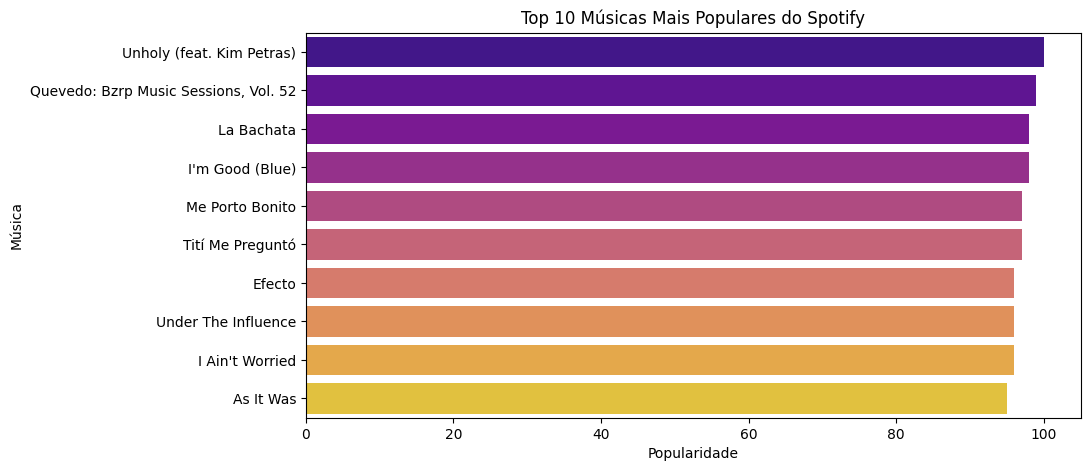

In [9]:
top_10_musicas = df.sort_values(by='popularity', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_10_musicas, x='popularity', y='track_name', hue='track_name', legend=False, palette='plasma')

plt.title('Top 10 Músicas Mais Populares do Spotify')
plt.xlabel('Popularidade')
plt.ylabel('Música')

plt.show()

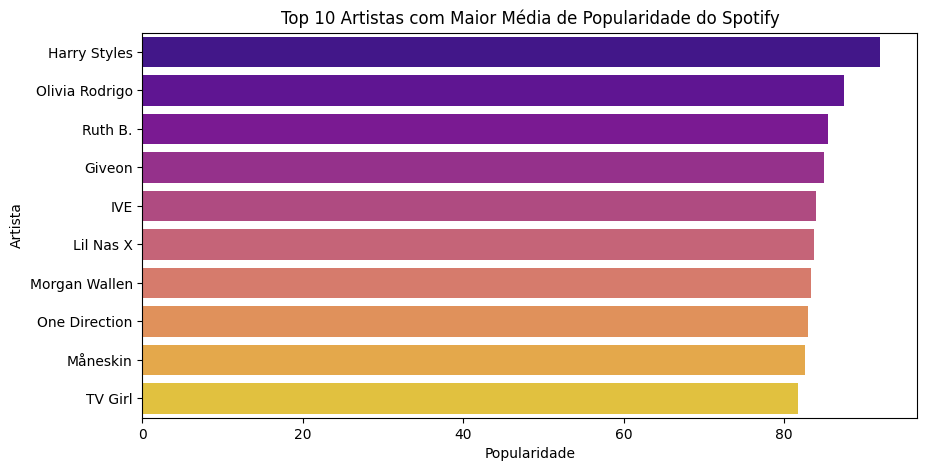

In [10]:
# Em músicas com mais de um artista, o nome do artista é uma junção do nome de todos presentes na música. Eu separei todos artistas.
artistas_sep = df[['artists', 'popularity']].copy()

artistas_sep['artists'] = df['artists'].str.split(';')
artistas_sep = artistas_sep.explode('artists')
artistas_sep['artists'] = artistas_sep['artists'].str.strip()

# Decidi fazer o top 10 baseado na média, então apliquei filtros de ter pelo menos 2 músicas do artista, e removi músicas com 0 de popularidade.
artistas_stats = artistas_sep[artistas_sep['popularity'] > 0]
artistas_stats = artistas_stats.groupby('artists')['popularity'].agg(['mean', 'count'])
top_10_artistas = artistas_stats[artistas_stats['count'] >= 2].sort_values(by='mean', ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top_10_artistas, x='mean', y='artists', hue='artists', legend=False, palette='plasma')

plt.title('Top 10 Artistas com Maior Média de Popularidade do Spotify')
plt.xlabel('Popularidade')
plt.ylabel('Artista')

plt.show()

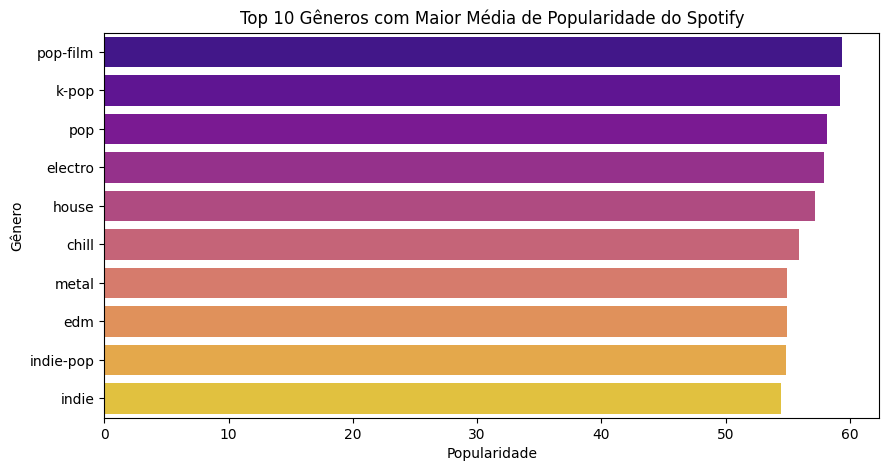

In [11]:
generos_stats = df_bruto[df_bruto['popularity'] > 0].dropna()
generos_stats = generos_stats.groupby('track_genre')['popularity'].agg(['mean', 'count'])
top_10_generos = generos_stats[generos_stats['count'] >= 2].sort_values(by='mean', ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top_10_generos, x='mean', y='track_genre', hue='track_genre', legend=False, palette='plasma')

plt.title('Top 10 Gêneros com Maior Média de Popularidade do Spotify')
plt.xlabel('Popularidade')
plt.ylabel('Gênero')

plt.show()

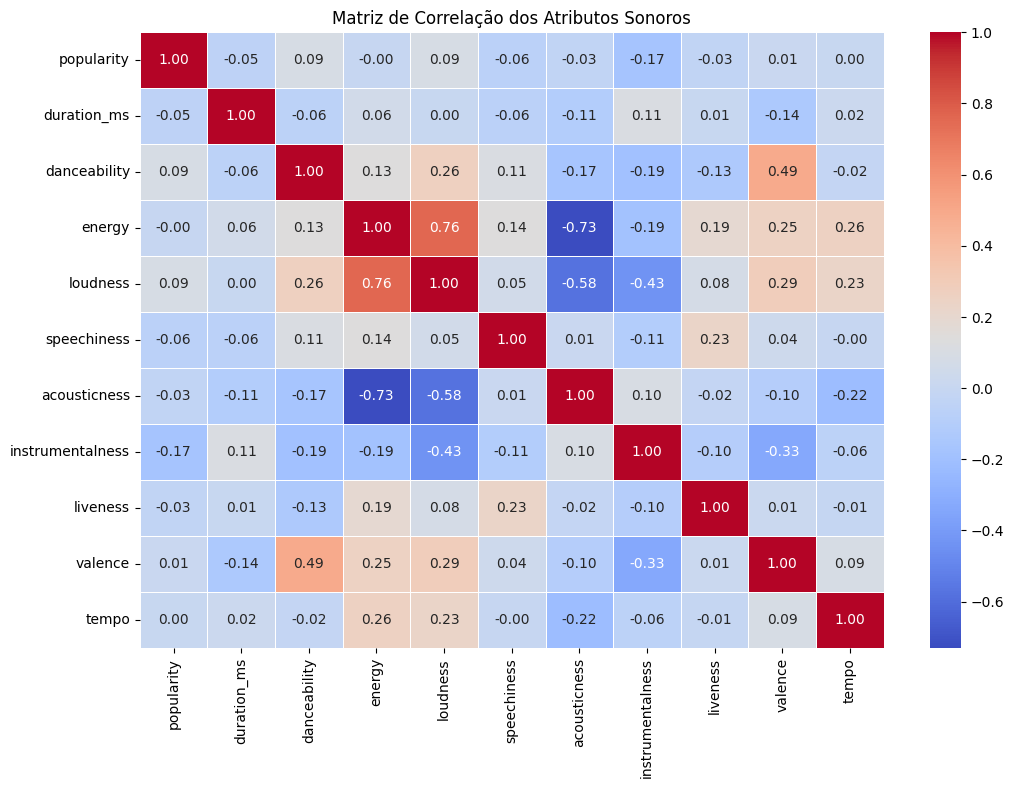

In [12]:
colunas_numericas = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
matriz_corr = df[colunas_numericas].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)

plt.title('Matriz de Correlação dos Atributos Sonoros')

plt.show()

## Conclusões sobre a matriz de correlação

*   Músicas barulhentas são mais enérgicas.
*   Faixas acústicas são menos barulhentas e enérgicas.
*   Músicas positivas e alegres dão mais vontade de dançar.
*   Essas características sonoras não influenciam muito a popularidade.